In [77]:
#All imports required
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

Part A:
 Reading the data, and transforming the data frame so we have a final data frame which we can work with. This includes retaining only one year(the year 2024), retaining the 11 features and making the dataframe such that rows are countries with columns as features.

In [78]:
main=pd.read_csv("WDICSV.csv")
main=main[['Country Name', 'Country Code', 'Indicator Name', 'Indicator Code', '2024']] #dropping all years besides year I'm taking into consideration
keep=['NY.GDP.PCAP.CD','NY.GDP.MKTP.KD.ZG','FP.CPI.TOTL.ZG','SL.UEM.TOTL.ZS','NE.TRD.GNFS.ZS','NE.GDI.TOTL.ZS','SP.DYN.LE00.IN','SP.URB.TOTL.IN.ZS','IT.NET.USER.ZS','EG.ELC.ACCS.ZS','SE.SEC.ENRR' ]
main=main[main['Indicator Code'].isin(keep)]

wide = main.pivot(index=['Country Name', 'Country Code'],
                  columns='Indicator Code',
                  values='2024').reset_index()
meta = pd.read_csv("WDICountry.csv")
countries = meta.loc[meta['Region'].notna(), 'Country Code']

wide = wide[wide['Country Code'].isin(countries)].reset_index(drop=True)


In [79]:
#Merging with API metadata to get the lenging type, region and income group features
import requests

url = "https://api.worldbank.org/v2/country?format=json&per_page=400"
meta = pd.json_normalize(requests.get(url).json()[1])

meta = meta[['id', 'region.value', 'lendingType.value', 'incomeLevel.value']]
meta.columns = ['Country Code', 'Region', 'LendingType', 'IncomeGroup']
meta = meta[meta['Region'] != 'Aggregates']

df = wide.merge(meta, on='Country Code')

Part B: Performing EDA
1) Inspect the dataset

In [80]:
print("Dataset Shape:", df.shape)  # Rows, Columns
print("\n--- Data Types & Non-Null Counts ---")
print(df.info())

# 2. View First/Last Rows
print("\n--- Head ---")
print(df.head(5))

# 3. Check for Duplicate Records
duplicate_count = df.duplicated().sum()
print(f"\nDuplicate Rows: {duplicate_count}")

Dataset Shape: (217, 16)

--- Data Types & Non-Null Counts ---
<class 'pandas.DataFrame'>
RangeIndex: 217 entries, 0 to 216
Data columns (total 16 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Country Name       217 non-null    str    
 1   Country Code       217 non-null    str    
 2   EG.ELC.ACCS.ZS     215 non-null    float64
 3   FP.CPI.TOTL.ZG     176 non-null    float64
 4   IT.NET.USER.ZS     182 non-null    float64
 5   NE.GDI.TOTL.ZS     169 non-null    float64
 6   NE.TRD.GNFS.ZS     172 non-null    float64
 7   NY.GDP.MKTP.KD.ZG  200 non-null    float64
 8   NY.GDP.PCAP.CD     200 non-null    float64
 9   SE.SEC.ENRR        109 non-null    float64
 10  SL.UEM.TOTL.ZS     182 non-null    float64
 11  SP.DYN.LE00.IN     217 non-null    float64
 12  SP.URB.TOTL.IN.ZS  217 non-null    float64
 13  Region             217 non-null    str    
 14  LendingType        217 non-null    str    
 15  IncomeGroup        217

In [81]:
# Missing Value Breakdown
missing_summary = pd.DataFrame({
    'Missing Count': df.isnull().sum(),
    'Percentage (%)': (df.isnull().sum() / len(df)) * 100
}).sort_values(by='Percentage (%)', ascending=False)

print(missing_summary[missing_summary['Missing Count'] > 0])

                   Missing Count  Percentage (%)
SE.SEC.ENRR                  108       49.769585
NE.GDI.TOTL.ZS                48       22.119816
NE.TRD.GNFS.ZS                45       20.737327
FP.CPI.TOTL.ZG                41       18.894009
IT.NET.USER.ZS                35       16.129032
SL.UEM.TOTL.ZS                35       16.129032
NY.GDP.MKTP.KD.ZG             17        7.834101
NY.GDP.PCAP.CD                17        7.834101
EG.ELC.ACCS.ZS                 2        0.921659


In [82]:
# Summary statistics for numerical features
summary = df[keep].describe().T
summary['skew'] = df[keep].skew()
summary['cv'] = summary['std'] / summary['mean'].abs() 
print(summary)

def iqr_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return s[(s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)]

by_country = df.set_index('Country Name')
for c in keep:
    out = iqr_outliers(by_country[c].dropna())
    if len(out):
        top = out.reindex(out.abs().sort_values(ascending=False).index).head(5).round(1)
        print(f"{c}: {len(out)} outliers, e.g. {top.to_dict()}")

                   count          mean           std         min          25%  \
NY.GDP.PCAP.CD     200.0  22364.353816  35312.896146  216.231929  2817.880677   
NY.GDP.MKTP.KD.ZG  200.0      3.141766      4.670727  -22.857327     1.662984   
FP.CPI.TOTL.ZG     176.0      7.407925     19.542513   -6.601186     1.720323   
SL.UEM.TOTL.ZS     182.0      6.721577      5.508973    0.130000     3.264250   
NE.TRD.GNFS.ZS     172.0     91.355653     55.389499    1.995412    51.409914   
NE.GDI.TOTL.ZS     169.0     23.046410      7.791052    0.252269    19.168208   
SP.DYN.LE00.IN     217.0     74.015940      7.106283   54.635000    68.739000   
SP.URB.TOTL.IN.ZS  217.0     62.868719     23.159924   14.657585    43.814849   
IT.NET.USER.ZS     182.0     72.541809     25.028044    8.596000    59.367650   
EG.ELC.ACCS.ZS     215.0     88.785581     21.216204    5.400000    89.750000   
SE.SEC.ENRR        109.0     91.405882     22.952760   19.866476    84.457237   

                           

Secondary School enrollment has the highest amount of missing values, at about 50 % missing values, followed by trade and gross capital formulation which both remain having about 20% missing values. All missing values will have to be dealt with and dropped accordingly.

Indicators with large differences across countries include economic output per person, annual GDP growth rate and annual consumer price inflation which all have a higher spread relative to mean than the others.


2) Analyze feature distribution

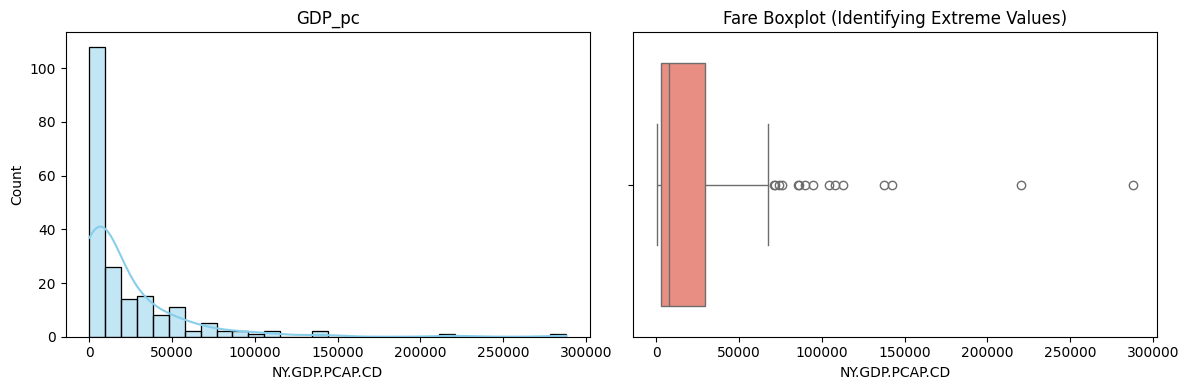

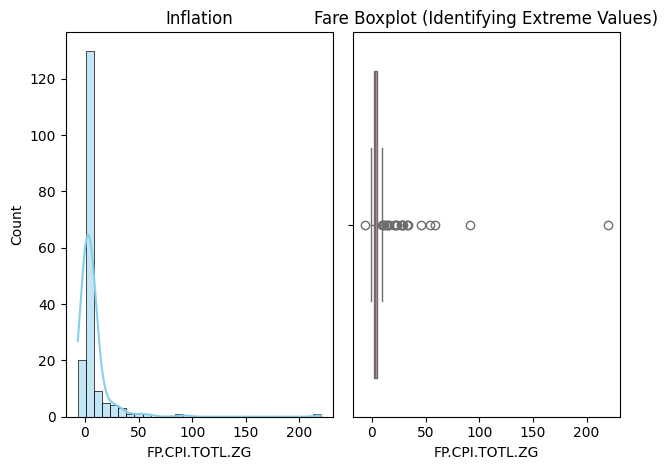

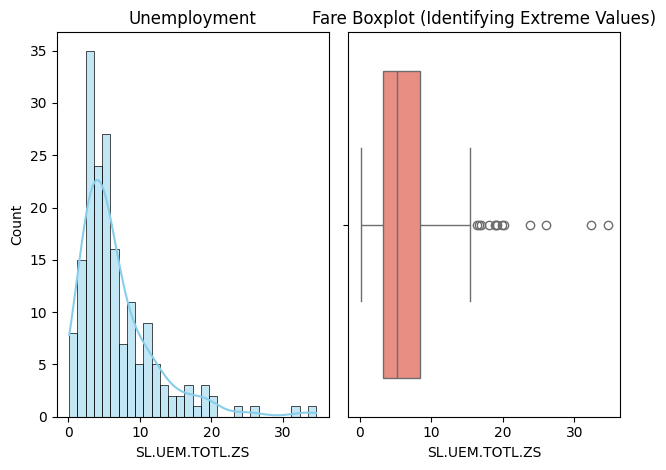

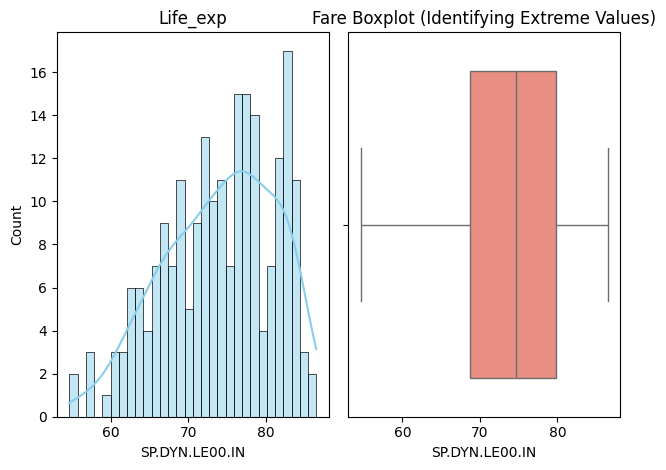

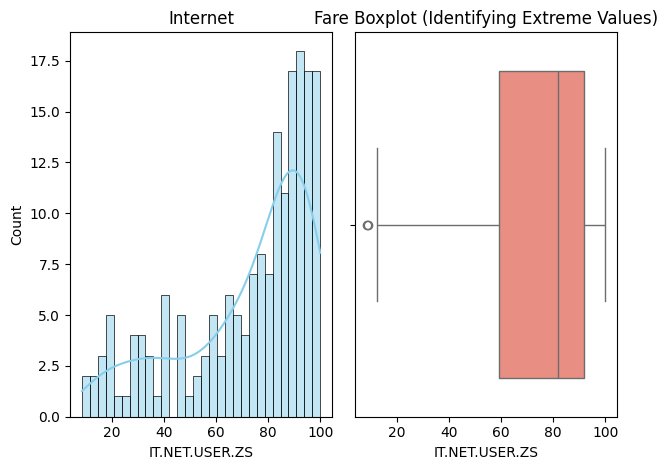

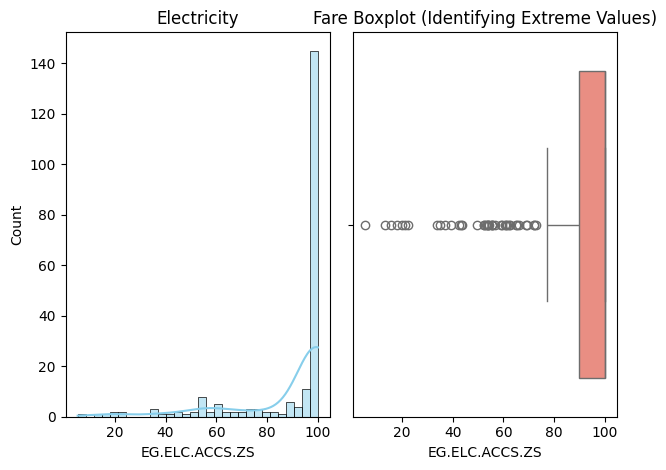

Skew normally 3.84
Skew of log transformation: -0.06


In [ ]:


short = {
    'NY.GDP.PCAP.CD':    'GDP_pc',        
    'NY.GDP.MKTP.KD.ZG': 'GDP_growth',    
    'FP.CPI.TOTL.ZG':    'Inflation',     
    'SL.UEM.TOTL.ZS':    'Unemployment', 
    'NE.TRD.GNFS.ZS':    'Trade',         
    'NE.GDI.TOTL.ZS':    'Investment',   
    'SP.DYN.LE00.IN':    'Life_exp',      
    'SP.URB.TOTL.IN.ZS': 'Urban',         
    'IT.NET.USER.ZS':    'Internet',      
    'EG.ELC.ACCS.ZS':    'Electricity',   
    'SE.SEC.ENRR':       'Sec_enrol',     
}

df['log_GDP_pc'] = np.log10(df['NY.GDP.PCAP.CD'])
plt.figure(figsize=(12, 4))
analyse=['NY.GDP.PCAP.CD','FP.CPI.TOTL.ZG','SL.UEM.TOTL.ZS','SP.DYN.LE00.IN','IT.NET.USER.ZS','EG.ELC.ACCS.ZS' ]
for x in analyse: 
    plt.subplot(1, 2, 1)
    sns.histplot(df[x], kde=True, bins=30, color='skyblue')
    plt.title(short[x])

    plt.subplot(1, 2, 2)
    sns.boxplot(x=df[x], color='salmon')
    plt.title('Fare Boxplot (Identifying Extreme Values)')
    print
    plt.tight_layout()
    plt.show()

print("For GDP")
print(f"Skew normally {df['NY.GDP.PCAP.CD'].skew():.2f}")
print(f"Skew of log transformation: {df['log_GDP_pc'].skew():.2f}")

We can see a significant left skewdness of electricity, and internet and signifcant right skewness of unemployment, inflation and GDP per captia. 
On applying the normal log 10 transformation to GDP the skew changes from 3.84 to -0.06 which is much better and makes the distribution symmetric thus making underlying distribution better for the ML model later


3) Compare known income groups

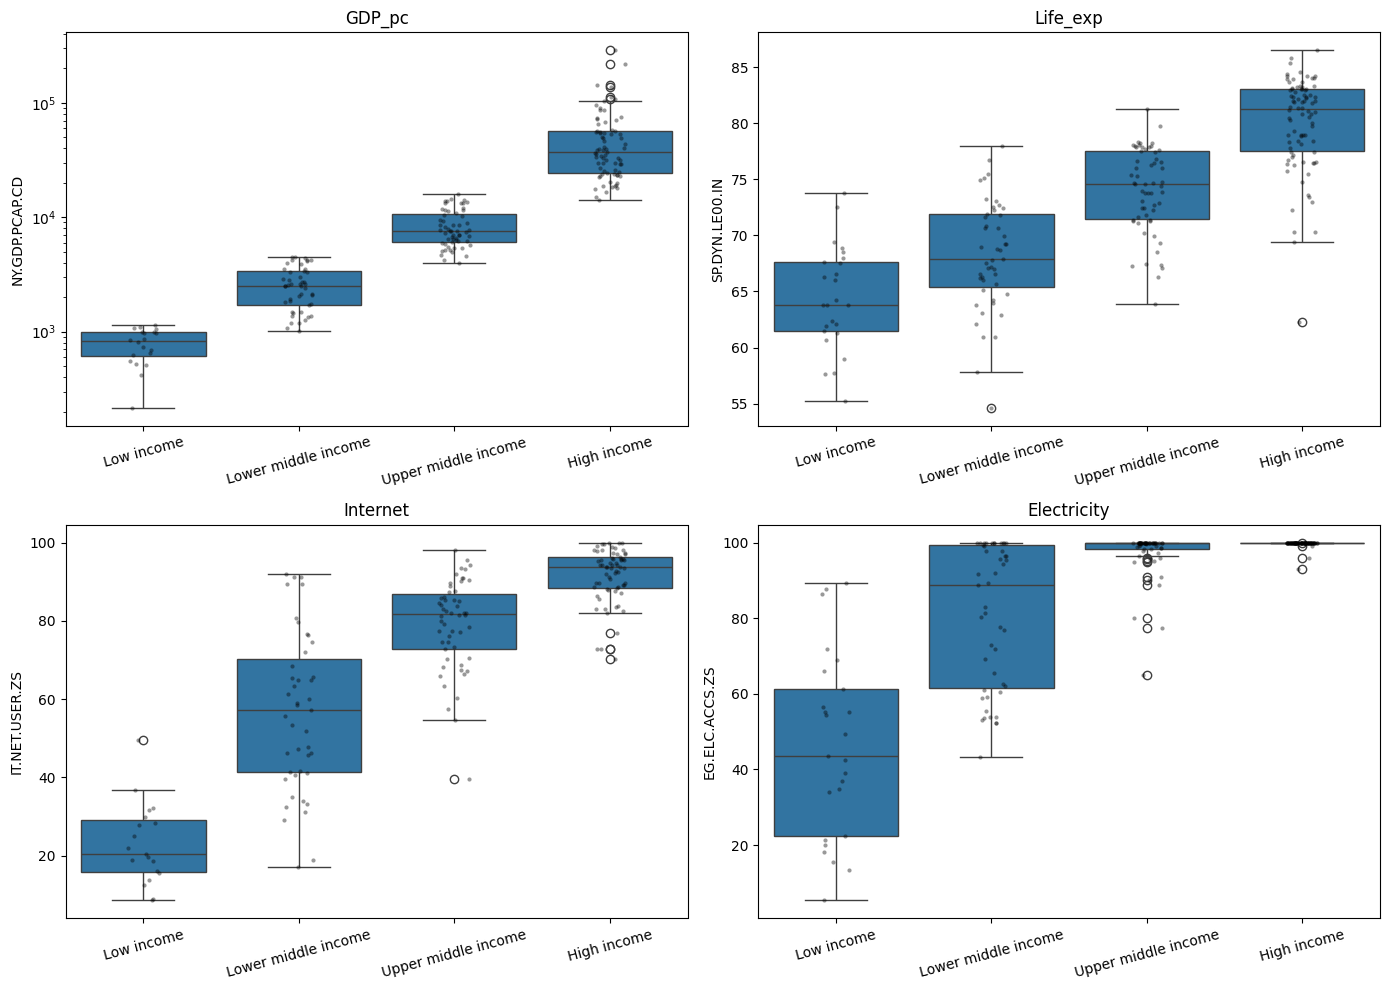

                     NY.GDP.PCAP.CD  SP.DYN.LE00.IN  IT.NET.USER.ZS  \
IncomeGroup                                                           
Low income                    829.1            63.8            20.5   
Lower middle income          2514.8            67.9            57.3   
Upper middle income          7584.6            74.5            81.8   
High income                 37506.8            81.3            93.8   

                     EG.ELC.ACCS.ZS  
IncomeGroup                          
Low income                     43.7  
Lower middle income            88.7  
Upper middle income           100.0  
High income                   100.0  


In [89]:
income_order=['Low income', 'Lower middle income', 'Upper middle income', 'High income']
grp = df[df['IncomeGroup'].isin(income_order)]  

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for ax, c in zip(axes.flat, ['NY.GDP.PCAP.CD','SP.DYN.LE00.IN','IT.NET.USER.ZS','EG.ELC.ACCS.ZS']):
    sns.boxplot(data=grp, x='IncomeGroup', y=c, order=income_order, ax=ax)
    sns.stripplot(data=grp, x='IncomeGroup', y=c, order=income_order, ax=ax,
                  color='black', size=3, alpha=0.4)
    if c =='NY.GDP.PCAP.CD':
        ax.set_yscale('log')      # log axis so all groups are visible
    ax.set_title(short[c]); ax.set_xlabel(''); ax.tick_params(axis='x', rotation=15)
plt.tight_layout(); plt.show()

print(grp.groupby('IncomeGroup')[['NY.GDP.PCAP.CD','SP.DYN.LE00.IN','IT.NET.USER.ZS','EG.ELC.ACCS.ZS']]
         .median().loc[income_order].round(1))

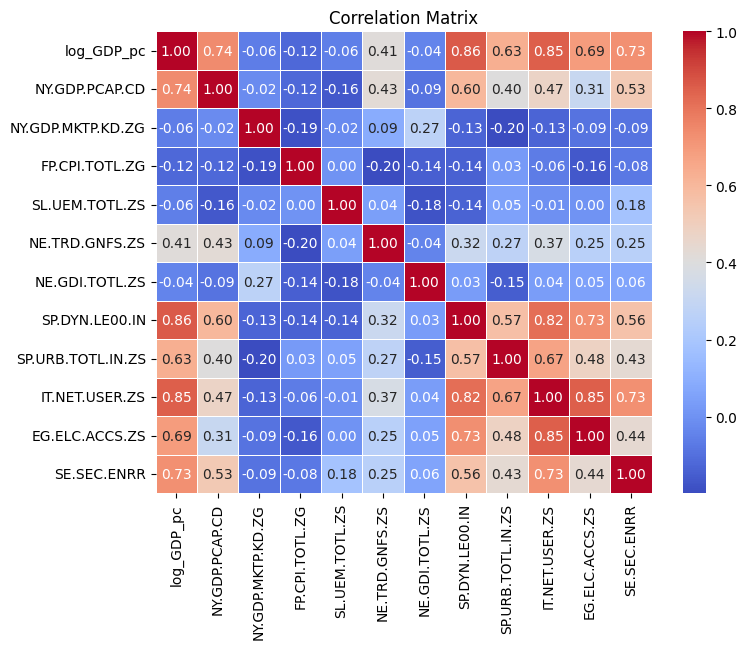

NameError: name 'corr' is not defined

In [92]:
# Correlation Matrix
num_cols =['log_GDP_pc'] + [c for c in keep if c != 'GDP_pc']
corr_matrix = df[num_cols].corr(method='pearson')

# Heatmap Visualization
plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Correlation Matrix')
plt.show()

pairs = corr_matrix.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
pairs = pairs.reindex(pairs.abs().sort_values(ascending=False).index)
print("Strongest pairs:\n", pairs.head(10).round(2))
print("\nPotentially redundant (|r| > 0.8):\n", pairs[pairs.abs() > 0.8].round(2))